#  PCA or SVD for GiftLane
**DS5020 Mini-Project, Aditya Vishwanath**

This notebook answers Sarah's two requests:
1. **Product pages:** a "Customers who bought this also bought…" box, built from a compressed version of the purchase data, that runs nightly and beats a best-seller list.
2. **Marketing:** one simple picture of the main customer groups.

**How to run:** click the Git cell at the bottom, then **Runtime → Run before**. The raw data lives in Google Drive and is never committed to Git. Every decision and its reason is recorded in `decision_log.md` (R1).

**Final model:** Truncated SVD, k = 50, binary purchase values, dot-product scoring. Hit rate at 10: **40.0%** vs **26.9%** for best sellers. Nightly job: **3.5 s**. Stored size: **3.7 MB** (vs 161 MB dense).

## Setup: connect Google Drive and enter the repo
**What this cell does:** Colab works on a copy of my GitHub repo stored in Google Drive. This cell (re)connects Drive, moves into the repo folder, sets my Git identity so commits are credited to the right person (R5, C1), pulls the latest version from GitHub, and makes sure the project folders exist.

`force_remount=True` and `os.chdir("/content")` fix the "Transport endpoint is not connected" error that appears when Colab loses its Drive connection.

In [1]:
import os
os.chdir("/content")                      # step out of any broken Drive folder first
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

%cd /content/drive/MyDrive/DS5020_project/DS5020_Mini_Project_Group_AMA
!git config user.name "adiv031198"
!git config user.email "aditya_vishwanath@alumni.sutd.edu.sg"
!git pull
!mkdir -p src notebooks reports data/interim data/processed

Mounted at /content/drive
/content/drive/MyDrive/DS5020_project/DS5020_Mini_Project_Group_AMA
Already up to date.


### Setup: check package versions
**What this cell does:** prints the versions of the main libraries. We need scikit-learn **1.4 or newer** because ML5 runs PCA directly on a sparse matrix (`svd_solver="arpack"`), which older versions cannot do. I used scikit-learn 1.6.1 on Python 3.13.

In [2]:
import sklearn, pandas, numpy, scipy
print(sklearn.__version__, pandas.__version__, numpy.__version__, scipy.__version__)

1.6.1 2.2.3 2.1.3 1.16.3


## DE1: Load both sheets of the raw data
**What this cell does:** loads the UCI Online Retail II file. Both Excel sheets (2009–2010 and 2010–2011) are combined into one table of **1,067,371 rows** and 8 columns.

**Why the caching:** reading the Excel file takes several minutes, so the first run saves a parquet copy and later runs load that in seconds.

**Decision (R1):** `Invoice` and `StockCode` are converted to text. They are identifiers, not numbers: invoices starting with "C" are cancellations, and product variants have letter suffixes (e.g. `85123A`). Without this, saving to parquet fails because the column mixes numbers and text.

In [3]:
import os
import pandas as pd

RAW = "/content/drive/MyDrive/DS5020_project/online_retail_II.xlsx"
CACHE = "data/interim/raw.parquet"

if os.path.exists(CACHE):
    df = pd.read_parquet(CACHE)                          # fast path: seconds
    print("Loaded cache:", df.shape)
else:
    sheets = pd.read_excel(RAW, sheet_name=None)          # slow path: a few minutes
    for name, s in sheets.items():
        print(name, s.shape)
    df = pd.concat(sheets.values(), ignore_index=True)
    # IDs are text, not numbers: Invoice has 'C' prefixes, StockCode has letter suffixes
    for col in ["Invoice", "StockCode", "Description", "Country"]:
        df[col] = df[col].astype("string")
    df.to_parquet(CACHE)
    print("Read Excel and saved cache:", df.shape)

print(df.columns.tolist(), len(df))
print(df.dtypes)

Loaded cache: (1067371, 8)
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country'] 1067371
Invoice        string[python]
StockCode      string[python]
Description    string[python]
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country        string[python]
dtype: object


### DE1: Data profile
**What this cell does:** for each column, reports its type, number and share of missing values, and number of unique values, and saves the table to `reports/data_profile.csv`.

**What I found, and how each finding becomes a cleaning rule in DE2:**
- **Customer ID is missing on 22.77% of lines** (guest checkouts). These cannot go in a customer × product matrix.
- **Quantity ranges from −80,995 to +80,995:** negative values are returns and cancellations.
- **Price goes as low as −£53,594:** accounting adjustments ("Adjust bad debt"), not purchases.
- **19,494 cancellation lines** (Invoice starts with "C").
- **5,305 stock codes but 5,698 descriptions:** some codes have several names, so we use `StockCode`, never `Description`, as the product ID.

In [4]:
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
profile.to_csv("reports/data_profile.csv")
print(profile)
print(df.drop(columns="Customer ID").describe())   # Customer ID min/max are real IDs (R4)
print("Cancellations:", df["Invoice"].astype(str).str.startswith("C").sum())

                      dtype  missing  missing_%  unique
Invoice              string        0       0.00   53628
StockCode            string        0       0.00    5305
Description          string     4382       0.41    5698
Quantity              int64        0       0.00    1057
InvoiceDate  datetime64[ns]        0       0.00   47635
Price               float64        0       0.00    2807
Customer ID         float64   243007      22.77    5942
Country              string        0       0.00      43
           Quantity                    InvoiceDate         Price
count  1.067371e+06                        1067371  1.067371e+06
mean   9.938898e+00  2011-01-02 21:13:55.394028544  4.649388e+00
min   -8.099500e+04            2009-12-01 07:45:00 -5.359436e+04
25%    1.000000e+00            2010-07-09 09:46:00  1.250000e+00
50%    3.000000e+00            2010-12-07 15:28:00  2.100000e+00
75%    1.000000e+01            2011-07-22 10:23:00  4.150000e+00
max    8.099500e+04            2011-12-09

### DE1: Write the requirements file (R6)
**What this cell does:** looks up the exact installed version of each package we use and writes `requirements.txt`, so anyone can rebuild the same environment. I list only the packages I used, because `pip freeze` in Colab lists hundreds.

In [5]:
import importlib.metadata as md
pkgs = ["pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "openpyxl", "pyarrow"]
lines = [f"{p}=={md.version(p)}" for p in pkgs]
open("requirements.txt", "w").write("\n".join(lines) + "\n")
print("\n".join(lines))

pandas==2.2.3
numpy==2.1.3
scipy==1.16.3
scikit-learn==1.6.1
matplotlib==3.10.0
openpyxl==3.1.5
pyarrow==23.0.1


## DE2: Clean the data, logging how many rows each rule removes
**What this cell does:** applies the cleaning rules one at a time, records the rows removed by each in `reports/cleaning_log.csv`, and saves the clean data.

**Rules, in order, and why:**
1. **Strip spaces from StockCode first.** We found `'47503J'` and `'47503J '` stored as two codes for the same product.
2. **Remove cancellations** (Invoice starts with "C"). This runs first so later rules don't double-count them.
3. **Remove lines without a Customer ID** (242,257 rows, the biggest loss).
4. **Remove Quantity ≤ 0.** This removed **0 rows**: every negative quantity was already a cancellation or a guest line.
5. **Remove Price ≤ 0** (71 rows of adjustments).
6. **Keep only real product codes:** 5 digits plus optional letters. This drops postage, fees, discounts and vouchers (2,917 rows).
7. **Remove exact duplicate rows** (26,055 likely double entries).

**Result:** 776,577 rows kept (72.8%), with 5,852 customers and 4,619 products.

In [6]:
import pandas as pd

df = pd.read_parquet("data/interim/raw.parquet")
df["StockCode"] = df["StockCode"].str.strip()   # fix hidden spaces, e.g. '47503J ' vs '47503J'
log = [("raw data", len(df), 0)]

def apply_rule(df, keep_mask, name):
    keep_mask = keep_mask.fillna(False)
    removed = int((~keep_mask).sum())
    df = df[keep_mask]
    log.append((name, len(df), removed))
    return df

df = apply_rule(df, ~df["Invoice"].str.startswith("C"), "remove cancellations (Invoice starts with C)")
df = apply_rule(df, df["Customer ID"].notna(), "remove lines without Customer ID")
df = apply_rule(df, df["Quantity"] > 0, "remove non-positive quantity")
df = apply_rule(df, df["Price"] > 0, "remove non-positive price")
df = apply_rule(df, df["StockCode"].str.fullmatch(r"\d{5}[A-Za-z]*"), "remove non-product codes")
df = apply_rule(df, ~df.duplicated(), "remove exact duplicate rows")

df["Customer ID"] = df["Customer ID"].astype(int)

cleaning_log = pd.DataFrame(log, columns=["step", "rows_after", "rows_removed"])
cleaning_log.to_csv("reports/cleaning_log.csv", index=False)
df.to_parquet("data/interim/clean.parquet")

print(cleaning_log.to_string(index=False))
print("\nCustomers:", df["Customer ID"].nunique(), "| Products:", df["StockCode"].nunique())
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

                                        step  rows_after  rows_removed
                                    raw data     1067371             0
remove cancellations (Invoice starts with C)     1047877         19494
            remove lines without Customer ID      805620        242257
                remove non-positive quantity      805620             0
                   remove non-positive price      805549            71
                    remove non-product codes      802632          2917
                 remove exact duplicate rows      776577         26055

Customers: 5852 | Products: 4619
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


### DE2 check 1: which codes did the product-code rule remove?
**What this cell does:** lists the codes that fail the "5 digits + letters" rule, with a description for each, so I can confirm by eye that no real products are being thrown away. It also confirms the space-stripping fix worked: `47503J` no longer appears in this list.

In [7]:
raw = pd.read_parquet("data/interim/raw.parquet")
raw["StockCode"] = raw["StockCode"].str.strip()
dropped = raw[~raw["StockCode"].str.fullmatch(r"\d{5}[A-Za-z]*").fillna(False)]
print(dropped.groupby("StockCode")["Description"].first().head(40))

StockCode
ADJUST          Adjustment by john on 26/01/2010 16
ADJUST2         Adjustment by Peter on Jun 25 2010 
AMAZONFEE                                AMAZON FEE
B                                   Adjust bad debt
BANK CHARGES                           Bank Charges
C2                                         CARRIAGE
C3                                             <NA>
CRUK                                CRUK Commission
D                                          Discount
DCGS0003                        BOXED GLASS ASHTRAY
DCGS0004                 HAYNES CAMPER SHOULDER BAG
DCGS0006                                       <NA>
DCGS0016                                       <NA>
DCGS0027                                       <NA>
DCGS0036                                       <NA>
DCGS0037                         KEY-RING CORKSCREW
DCGS0039                                       <NA>
DCGS0041           HAYNES MINI-COOPER PLAYING CARDS
DCGS0044                    HANDZ-OFF CAR FRESHENER
DC

### DE2 check 2: do the DCGS codes matter?
**What this cell does:** the `DCGS…` codes look like real items (dog collars, car fresheners, ashtrays), but not GiftLane gift-ware. This counts how many of their rows have a Customer ID.

**Result:** **0 rows.** Every DCGS sale was a guest or eBay order, so the Customer ID rule had already removed them all. No separate decision is needed.

In [8]:
clean_ish = raw[raw["Customer ID"].notna()]
dcgs = clean_ish[clean_ish["StockCode"].str.startswith("DCGS")]
print("DCGS rows:", len(dcgs), "| customers:", dcgs["Customer ID"].nunique(), "| codes:", dcgs["StockCode"].nunique())

DCGS rows: 0 | customers: 0 | codes: 0


### DE2 check 3: full list of removed codes with row counts
**What this cell does:** shows every removed code and how often it appears. They fall into clear groups: postage (POST, DOT, C2), manual entries and samples (M, S, PADS), fees and accounting (BANK CHARGES, AMAZONFEE, ADJUST, B, D), gift vouchers (`gift_0001_*`), test codes and DCGS items.

The only ambiguous code, **SP1002** (3 rows), is negligible and would fail the 10-customer filter in DE4 anyway. These counts include guest lines, so they add up to more than the 2,917 rows DE2 removed.

In [9]:
print(dropped["StockCode"].value_counts().to_string())

StockCode
POST            2122
DOT             1446
M               1421
C2               282
D                177
S                104
BANK CHARGES     102
ADJUST            67
AMAZONFEE         43
DCGS0058          31
gift_0001_20      29
gift_0001_30      29
DCGSSGIRL         25
DCGSSBOY          23
PADS              19
CRUK              16
gift_0001_10      16
DCGS0076          15
TEST001           15
DCGS0003          14
gift_0001_50       8
gift_0001_40       7
B                  6
DCGS0069           6
DCGS0004           5
m                  5
gift_0001_80       4
DCGS0066N          4
DCGS0072           4
DCGS0068           3
DCGS0070           3
SP1002             3
gift_0001_70       3
ADJUST2            3
TEST002            2
gift_0001_60       2
DCGS0037           2
gift_0001_90       2
DCGS0062           2
DCGS0016           1
DCGS0044           1
DCGS0006           1
DCGSLBOY           1
GIFT               1
DCGS0027           1
DCGS0036           1
DCGSLGIRL          1
DCG

## DE3: Time-based split and held-out test purchases (R2)
**What this cell does:** the data ends on 9 Dec 2011, so everything from **9 Oct 2011** onwards is the test period, and everything before is training. No model ever sees the test period.

**What the model must predict:** for each customer who appears in both periods, the products they bought in the test period but **never bought before**. Re-orders are excluded, because a recommender is not needed to suggest things a customer already buys.

**Results:**
- 660,194 training rows and 116,383 test rows.
- **378 of 2,420 test customers are new** (16%). With no history they can't be personalised (the cold-start problem, a risk for the memo).
- **1,930 customers** bought at least one new product, giving 49,423 target pairs (25.6 per customer on average; these are wholesalers).

In [10]:
import pandas as pd

df = pd.read_parquet("data/interim/clean.parquet")

# Last 2 months = test period (R2)
cutoff = df["InvoiceDate"].max() - pd.DateOffset(months=2)
train = df[df["InvoiceDate"] < cutoff]
test = df[df["InvoiceDate"] >= cutoff]

# Held-out targets: products a returning customer bought in the test period but never in training
train_pairs = train[["Customer ID", "StockCode"]].drop_duplicates()
test_pairs = test[["Customer ID", "StockCode"]].drop_duplicates()
test_pairs = test_pairs[test_pairs["Customer ID"].isin(train["Customer ID"])]
targets = test_pairs.merge(train_pairs, how="left", indicator=True)
targets = targets[targets["_merge"] == "left_only"].drop(columns="_merge")

train.to_parquet("data/processed/train.parquet")
targets.to_parquet("data/processed/test_targets.parquet")

print("Cutoff:", cutoff)
print("Train rows:", len(train), "| Test rows:", len(test))
print("Test customers total:", test["Customer ID"].nunique())
print("  with training history:", test_pairs["Customer ID"].nunique())
print("  new (dropped, cold start):", test["Customer ID"].nunique() - test_pairs["Customer ID"].nunique())
print("Customers with at least 1 new product:", targets["Customer ID"].nunique())
print("Target pairs:", len(targets), "| per customer (mean):", round(targets.groupby("Customer ID").size().mean(), 1))

Cutoff: 2011-10-09 12:50:00
Train rows: 660194 | Test rows: 116383
Test customers total: 2420
  with training history: 2042
  new (dropped, cold start): 378
Customers with at least 1 new product: 1930
Target pairs: 49423 | per customer (mean): 25.6


## DE4: Build the sparse customer × product matrix (training data only)
**What this cell does:** turns the training rows into matrix **A**, with one row per customer and one column per product.

**Decisions (R1):**
- **Aggregate first, then transform:** quantities are summed per customer-product pair *before* taking the log. Otherwise a product bought on 5 invoices would get 5 log values added together.
- **Purchase value: `log(1 + quantity)`.** This stops one order of 10,000 napkins from dominating. (ML7 later shows that a 1/0 "ever bought" flag works slightly better, so the model converts this matrix to 1/0.)
- **Product filter: bought by at least 10 customers.** Products with very few buyers can't be placed reliably. This keeps 3,687 of 4,529 products.
- **Sorted indices:** rows and columns are in sorted order, so rebuilding gives an identical matrix.

**Check:** **90.5%** of test targets are still recommendable after the filter. The 9.5% we lose are rare products. The index files contain customer IDs, so they stay in the gitignored `data/` folder (R4).

In [11]:
import numpy as np, pandas as pd, scipy.sparse as sp

train = pd.read_parquet("data/processed/train.parquet")
targets = pd.read_parquet("data/processed/test_targets.parquet")

# One row per customer-product pair (aggregate BEFORE taking log)
agg = train.groupby(["Customer ID", "StockCode"], as_index=False)["Quantity"].sum()

# Product filter: bought by at least 10 customers
MIN_CUSTOMERS = 10
n_buyers = agg.groupby("StockCode")["Customer ID"].nunique()
keep_products = n_buyers[n_buyers >= MIN_CUSTOMERS].index
agg = agg[agg["StockCode"].isin(keep_products)]

# Index maps (sorted, so the matrix is reproducible)
customers = np.sort(agg["Customer ID"].unique())
products = np.sort(agg["StockCode"].unique())
cust_idx = {c: i for i, c in enumerate(customers)}
prod_idx = {p: j for j, p in enumerate(products)}

rows = agg["Customer ID"].map(cust_idx).values
cols = agg["StockCode"].map(prod_idx).values
vals = np.log1p(agg["Quantity"].values)
A = sp.csr_matrix((vals, (rows, cols)), shape=(len(customers), len(products)))

# Keep only test targets the model could possibly recommend
before = len(targets)
targets = targets[targets["Customer ID"].isin(cust_idx) & targets["StockCode"].isin(prod_idx)]

# Save
sp.save_npz("data/processed/A_train.npz", A)
pd.Series(customers, name="Customer ID").to_csv("data/processed/customer_index.csv", index_label="row")
pd.Series(products, name="StockCode").to_csv("data/processed/product_index.csv", index_label="col")
targets.to_parquet("data/processed/test_targets_filtered.parquet")

print("Products before filter:", n_buyers.size, "| kept:", len(products))
print("Matrix shape:", A.shape)
print("Targets kept:", len(targets), "of", before, f"({len(targets)/before:.1%})")
print("Eval customers:", targets["Customer ID"].nunique())

Products before filter: 4529 | kept: 3687
Matrix shape: (5473, 3687)
Targets kept: 44727 of 49423 (90.5%)
Eval customers: 1913


## DE5: Matrix report
**What this cell does:** reports the matrix's size and how empty it is, saved to `reports/matrix_report.csv`.

**Results:** 5,473 customers × 3,687 products, 413,927 non-zero cells, **97.95% sparse** (only about 2 cells in 100 are filled). A dense copy would need **161.4 MB**; stored sparse it needs **5.0 MB**. This sparsity is the main reason I chose Truncated SVD (see ML1 in the decision log).

In [12]:
n_rows, n_cols = A.shape
dense_mb = n_rows * n_cols * 8 / 1e6
sparse_mb = (A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 1e6
report = pd.DataFrame({
    "measure": ["customers (rows)", "products (cols)", "non-zeros", "sparsity %",
                "dense memory (MB)", "sparse memory (MB)"],
    "value": [n_rows, n_cols, A.nnz, round(100 * (1 - A.nnz / (n_rows * n_cols)), 2),
              round(dense_mb, 1), round(sparse_mb, 1)],
})
report.to_csv("reports/matrix_report.csv", index=False)
print(report.to_string(index=False))

           measure     value
  customers (rows)   5473.00
   products (cols)   3687.00
         non-zeros 413927.00
        sparsity %     97.95
 dense memory (MB)    161.40
sparse memory (MB)      5.00


## DE6: One-command rebuild and reproducibility check (R6)
**What this cell does:** `build_matrix.py` combines DE1 to DE5 into one script, so the whole data pipeline reruns with a single command. This cell backs up the matrix built by the notebook, runs the script, and compares the two matrices.

**Expected result:** `Same shape: True | Differences: 0`. That proves the script reproduces the notebook exactly. The script also accepts options (`--min-customers`, `--test-months`, `--value`) for trying other settings.

In [13]:
# Back up the notebook-built matrix, rebuild with the one-command script (R6), and check they are identical
!cp data/processed/A_train.npz data/processed/A_train_notebook.npz
!python build_matrix.py --raw "{RAW}"

import scipy.sparse as sp
old = sp.load_npz("data/processed/A_train_notebook.npz")
new = sp.load_npz("data/processed/A_train.npz")
print("Same shape:", old.shape == new.shape, "| Differences:", (abs(old - new) > 1e-12).nnz)

[DE1] loading cache data/interim/raw.parquet
[DE1] 1,067,371 rows, columns ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
[DE2] cleaning log:
                                        step  rows_after  rows_removed
                                    raw data     1067371             0
remove cancellations (Invoice starts with C)     1047877         19494
            remove lines without Customer ID      805620        242257
                remove non-positive quantity      805620             0
                   remove non-positive price      805549            71
                    remove non-product codes      802632          2917
                 remove exact duplicate rows      776577         26055
[DE3] cutoff 2011-10-09 12:50:00 | train 660,194 rows | test 116,383 rows
      test customers 2,420, returning 2,042, with new products 1,930, target pairs 49,423
[DE4] products 4,529 -> kept 3,687 (min 10 customers), value = log1p
  

## ML2: How much information is lost for each k?
**What this cell does:** fits Truncated SVD for k = 10, 20, 50, 100 and 200 components, and plots the relative reconstruction error ‖A − A_k‖ / ‖A‖.

**Shortcut used:** the error is computed from the singular values alone, so the 161 MB dense matrix is never built.

**Result:** the curve falls smoothly with no clear elbow: 0.876 at k = 10 down to 0.639 at k = 200. At k = 50 the components keep about 38% of the signal (1 − 0.790²). That is normal for purchase data: what's lost is mostly one-off individual orders, not the shared buying patterns a recommender needs. **So k is chosen by hit rate (next cell), not by this curve.**

k= 10  fit  0.19s  rel. error 0.876  factors 0.73 MB
k= 20  fit  0.32s  rel. error 0.846  factors 1.47 MB
k= 50  fit  0.49s  rel. error 0.790  factors 3.66 MB
k=100  fit  0.96s  rel. error 0.728  factors 7.33 MB
k=200  fit  1.93s  rel. error 0.639  factors 14.66 MB


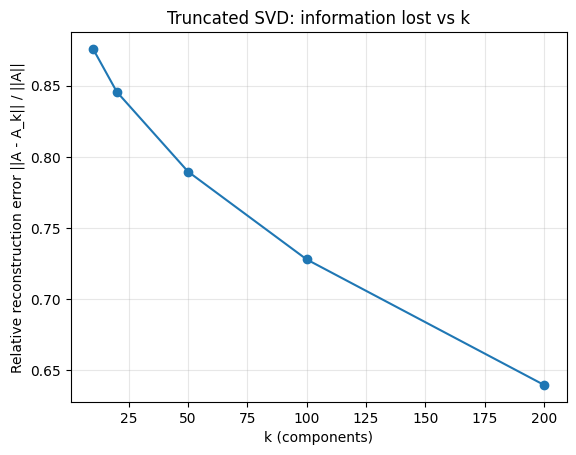

In [14]:
import numpy as np, scipy.sparse as sp, time
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD

A = sp.load_npz("data/processed/A_train.npz")
A_norm_sq = A.multiply(A).sum()          # ||A||_F squared

results = []
for k in [10, 20, 50, 100, 200]:
    t = time.time()
    svd = TruncatedSVD(n_components=k, random_state=42).fit(A)
    fit_s = time.time() - t
    rel_err = np.sqrt(1 - (svd.singular_values_ ** 2).sum() / A_norm_sq)
    factor_mb = (A.shape[0] + A.shape[1]) * k * 8 / 1e6
    results.append((k, round(fit_s, 2), round(rel_err, 4), round(factor_mb, 2)))
    print(f"k={k:>3}  fit {fit_s:5.2f}s  rel. error {rel_err:.3f}  factors {factor_mb:.2f} MB")

ks, _, errs, _ = zip(*results)
plt.plot(ks, errs, marker="o")
plt.xlabel("k (components)"); plt.ylabel("Relative reconstruction error ||A - A_k|| / ||A||")
plt.title("Truncated SVD: information lost vs k"); plt.grid(alpha=0.3)
plt.savefig("reports/ml2_reconstruction_error.png", dpi=150, bbox_inches="tight")
plt.show()

## ML3 + ML4: Recommendations and hit rate for each k, vs the best-seller baseline (R3)
**What this cell does:**
- **Baseline:** recommends the 10 best-selling products (by number of buyers) that the customer hasn't already bought.
- **Model (first version):** scores each product by the sum of its *cosine* similarity to everything the customer bought, then takes the top 10.
- **Hit rate at 10:** the share of the 1,913 test customers for whom at least one of their real next purchases is in the top 10.

Both methods exclude products the customer already owns, so the comparison is fair.

**Result:** the best-seller baseline scores **26.9%**, and this first model only **14.8–22.7%**, so it *loses*. The next cell explains why and fixes it.

In [15]:
import numpy as np, pandas as pd, scipy.sparse as sp, time
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

A = sp.load_npz("data/processed/A_train.npz")
customers = pd.read_csv("data/processed/customer_index.csv")["Customer ID"].values
products = pd.read_csv("data/processed/product_index.csv", dtype={"StockCode": str})["StockCode"].values
targets = pd.read_parquet("data/processed/test_targets_filtered.parquet")

cust_idx = {c: i for i, c in enumerate(customers)}
prod_idx = {p: j for j, p in enumerate(products)}
targets["row"] = targets["Customer ID"].map(cust_idx)
targets["col"] = targets["StockCode"].map(prod_idx)
target_sets = targets.groupby("row")["col"].apply(set)
eval_rows = target_sets.index.values
A_eval = A[eval_rows]
bought_r, bought_c = A_eval.nonzero()

def top_n(scores, n=10):
    scores[bought_r, bought_c] = -np.inf            # never recommend what they already bought
    return np.argpartition(-scores, n, axis=1)[:, :n]

def hit_rate(top):
    return np.mean([len(target_sets[r] & set(top[i])) > 0 for i, r in enumerate(eval_rows)])

# Baseline (R3): 10 best sellers (by number of buyers) the customer has not bought
popularity = np.diff(A.tocsc().indptr).astype(float)
base_scores = np.tile(popularity, (len(eval_rows), 1))
base_hr = hit_rate(top_n(base_scores))
print(f"Best-seller baseline hit@10: {base_hr:.3f}")

# Model: score = sum of cosine similarities to what the customer bought, weighted by log1p quantity
results = []
for k in [10, 20, 50, 100, 200]:
    svd = TruncatedSVD(n_components=k, random_state=42).fit(A)
    P = normalize(svd.components_.T)                 # one unit-length row per product
    t = time.time()
    scores = (A_eval @ P) @ P.T
    hr = hit_rate(top_n(scores))
    results.append((k, round(hr, 3), round(time.time() - t, 2)))
    print(f"k={k:>3}  hit@10 {hr:.3f}  scoring {results[-1][2]}s")

res = pd.DataFrame(results, columns=["k", "hit_rate_at_10", "scoring_seconds"])
res["baseline_hit_rate_at_10"] = round(base_hr, 3)
res.to_csv("reports/ml4_hit_rate_by_k.csv", index=False)
res

Best-seller baseline hit@10: 0.269
k= 10  hit@10 0.148  scoring 0.18s
k= 20  hit@10 0.183  scoring 0.19s
k= 50  hit@10 0.215  scoring 0.2s
k=100  hit@10 0.227  scoring 0.36s
k=200  hit@10 0.216  scoring 1.78s


,k,hit_rate_at_10,scoring_seconds,baseline_hit_rate_at_10
0,10,0.148,0.18,0.269
1,20,0.183,0.19,0.269
2,50,0.215,0.20,0.269
3,100,0.227,0.36,0.269
4,200,0.216,1.78,0.269


### ML4 / ML7: Fixing the scoring (cosine vs dot product) and testing purchase values
**Why the first model lost:** cosine similarity makes every product vector the same length, so a niche product bought by 12 people counts the same as a hit bought by 2,000. The test period (Oct-Dec) is also Christmas season, when wholesalers stock up on best sellers.

**What this cell does:** compares cosine scoring with **dot-product** scoring, which uses the rebuilt matrix A_k directly and keeps popularity. It also compares **log1p** values with **1/0** values (ML7, the sensitivity analysis).

**Result:** dot product wins everywhere, at **35–40%**. 1/0 values are slightly better than log1p. **Chosen model: 1/0 values, k = 50, dot product: 40.0% vs 26.9% for best sellers.** k = 100 gives 40.3%, but that difference is within noise (standard error ≈ 1.1 points), and k = 50 is half the size.

*Limitation:* k and the scoring method were chosen using the test period, not a separate validation period.

In [16]:
B = A.copy(); B.data[:] = 1.0                     # 1/0 "ever bought" version of the matrix
variants = {"log1p": A, "binary": B}

rows_out = []
for name, M in variants.items():
    M_eval = M[eval_rows]
    for k in [20, 50, 100, 200]:
        svd = TruncatedSVD(n_components=k, random_state=42).fit(M)
        V = svd.components_.T
        hr_dot = hit_rate(top_n((M_eval @ V) @ V.T))
        P = normalize(V)
        hr_cos = hit_rate(top_n((M_eval @ P) @ P.T))
        rows_out.append((name, k, round(hr_cos, 3), round(hr_dot, 3)))
        print(f"{name:6}  k={k:>3}  cosine {hr_cos:.3f}  dot {hr_dot:.3f}  (baseline {base_hr:.3f})")

variants_df = pd.DataFrame(rows_out, columns=["value", "k", "hit_cosine", "hit_dot"])
variants_df.to_csv("reports/ml4_scoring_variants.csv", index=False)

log1p   k= 20  cosine 0.183  dot 0.350  (baseline 0.269)
log1p   k= 50  cosine 0.215  dot 0.378  (baseline 0.269)
log1p   k=100  cosine 0.227  dot 0.389  (baseline 0.269)
log1p   k=200  cosine 0.216  dot 0.398  (baseline 0.269)
binary  k= 20  cosine 0.197  dot 0.376  (baseline 0.269)
binary  k= 50  cosine 0.236  dot 0.400  (baseline 0.269)
binary  k=100  cosine 0.247  dot 0.403  (baseline 0.269)
binary  k=200  cosine 0.239  dot 0.393  (baseline 0.269)


## ML3: Product-page "also bought" sanity check
**What this cell does:** builds the product-page function. For a product, it finds the most similar products by cosine similarity of their SVD factor vectors, then prints suggestions for the 3 best sellers with real product names.

**Result:** the suggestions make sense to a human: T-light holder → other T-light holders and a lantern; Regency cakestand → Regency teacups and teapot; cake cases → other cake cases. The model learned these themes from purchases alone, without reading descriptions.

**Observation:** suggestions lean toward variants of the same product rather than complementary items, which could feel repetitive on a product page (a next step for the memo).

In [17]:
clean = pd.read_parquet("data/interim/clean.parquet")
names = clean.groupby("StockCode")["Description"].agg(lambda s: s.mode().iat[0] if s.notna().any() else "")
name_of = lambda j: names.get(products[j], "")

B = A.copy(); B.data[:] = 1.0
svd = TruncatedSVD(n_components=50, random_state=42).fit(B)
V = svd.components_.T
P = normalize(V)

def also_bought(j, n=5):
    s = P @ P[j]
    s[j] = -np.inf
    return np.argsort(-s)[:n]

popular = np.argsort(-popularity)[:3]
for j in popular:
    print(f"\n{name_of(j)}")
    for m in also_bought(j):
        print("   ->", name_of(m))


WHITE HANGING HEART T-LIGHT HOLDER
   -> RED HANGING HEART T-LIGHT HOLDER
   -> CANDLEHOLDER PINK HANGING HEART
   -> COLOUR GLASS. STAR T-LIGHT HOLDER
   -> WHITE METAL LANTERN
   -> GLASS STAR FROSTED T-LIGHT HOLDER

REGENCY CAKESTAND 3 TIER
   -> ROSES REGENCY TEACUP AND SAUCER 
   -> GREEN REGENCY TEACUP AND SAUCER
   -> PINK REGENCY TEACUP AND SAUCER
   -> REGENCY TEAPOT ROSES 
   -> CAKE STAND LOVEBIRD 2 TIER PINK

PACK OF 72 RETROSPOT CAKE CASES
   -> PACK OF 60 PINK PAISLEY CAKE CASES
   -> PACK OF 60 DINOSAUR CAKE CASES
   -> 60 TEATIME FAIRY CAKE CASES
   -> PACK OF 60 MUSHROOM CAKE CASES
   -> 72 SWEETHEART FAIRY CAKE CASES


## ML4: Timing the full nightly job
**What this cell does:** times everything the overnight job would do: fit the model, build the top-10 "also bought" list for every product, and build a personal top-10 for every customer. Work is done in chunks of 1,000, so the full 161 MB score table never exists in memory.

**Result:** fit 1.15 s + product table 0.89 s + all 5,473 customers 1.42 s = **3.5 seconds in total**. Stored output: **3.66 MB** of factors plus **0.37 MB** of ready-made top-10 tables.

In [18]:
t0 = time.time()
svd = TruncatedSVD(n_components=50, random_state=42).fit(B)
V = svd.components_.T; P = normalize(V)
t_fit = time.time() - t0

t1 = time.time()
item_top10 = np.zeros((P.shape[0], 10), dtype=np.int32)
for s in range(0, P.shape[0], 1000):                       # chunks keep memory small
    sims = P[s:s+1000] @ P.T
    sims[np.arange(sims.shape[0]), np.arange(s, s + sims.shape[0])] = -np.inf
    item_top10[s:s+1000] = np.argpartition(-sims, 10, axis=1)[:, :10]
t_items = time.time() - t1

t2 = time.time()
cust_top10 = np.zeros((B.shape[0], 10), dtype=np.int32)
for s in range(0, B.shape[0], 1000):
    Bc = B[s:s+1000]
    sc = (Bc @ V) @ V.T
    r, c = Bc.nonzero(); sc[r, c] = -np.inf
    cust_top10[s:s+1000] = np.argpartition(-sc, 10, axis=1)[:, :10]
t_cust = time.time() - t2

print(f"Fit: {t_fit:.2f}s | product table: {t_items:.2f}s | all {B.shape[0]} customers: {t_cust:.2f}s")
print(f"TOTAL nightly job: {time.time() - t0:.2f}s")
print(f"Stored: factors {(V.nbytes + svd.transform(B).nbytes)/1e6:.2f} MB, "
      f"tables {(item_top10.nbytes + cust_top10.nbytes)/1e6:.2f} MB")

Fit: 0.52s | product table: 0.28s | all 5473 customers: 0.55s
TOTAL nightly job: 1.36s
Stored: factors 3.66 MB, tables 0.37 MB


## ML5: PCA vs Truncated SVD on the same matrix with the same k
**What this cell does:** runs both methods on the 1/0 matrix with k = 50 and measures what the comparison table needs: fit time, peak memory, stored size, variance explained or reconstruction error, hit rate, and what component 1 means. For a fair comparison, PCA's recommendations rebuild the centred data and add the average customer back (`+ mu`).

**Results:**
- **Hit rate:** PCA 40.4% vs SVD 40.0%, a tie within noise.
- **Fit time:** SVD is 3× faster (1.1 s vs 3.3 s).
- **Component 1 is the same in both:** it measures overall buying volume (correlation 0.98 with basket size), led by the best-selling staples.
- **Practical difference:** PCA needs the dense centred matrix at scoring time, which is the 161 MB table Sarah wants to avoid.

**Conclusion:** we keep Truncated SVD. *Note:* `tracemalloc` misses memory used inside the low-level solvers, so the peak-memory figures are underestimates.

In [19]:
import tracemalloc
from sklearn.decomposition import PCA

B_eval = B[eval_rows]
n_buyers_per_customer = np.asarray(B.sum(axis=1)).ravel()

def measure(make_model, X):
    tracemalloc.start()
    t = time.time()
    model = make_model().fit(X)
    fit_s = time.time() - t
    peak_mb = tracemalloc.get_traced_memory()[1] / 1e6
    tracemalloc.stop()
    return model, fit_s, peak_mb

# Truncated SVD
svd, svd_t, svd_mem = measure(lambda: TruncatedSVD(n_components=50, random_state=42), B)
V_svd = svd.components_.T
svd_err = np.sqrt(1 - (svd.singular_values_ ** 2).sum() / B.multiply(B).sum())
svd_hit = hit_rate(top_n((B_eval @ V_svd) @ V_svd.T))
svd_c1 = np.corrcoef(svd.transform(B)[:, 0], n_buyers_per_customer)[0, 1]

# PCA (implicit centring on sparse input)
pca, pca_t, pca_mem = measure(lambda: PCA(n_components=50, svd_solver="arpack", random_state=42), B)
V_pca = pca.components_.T
mu = pca.mean_
Xc = B_eval.toarray() - mu                       # centred eval customers
pca_hit = hit_rate(top_n(Xc @ V_pca @ V_pca.T + mu))
pca_c1 = np.corrcoef(pca.transform(B)[:, 0], n_buyers_per_customer)[0, 1]

factor_mb = (B.shape[0] + B.shape[1]) * 50 * 8 / 1e6
table = pd.DataFrame({
    "Measure": ["k used", "Fit time (s)", "Peak memory during fit (MB)", "Size of stored factors (MB)",
                "Variance explained / relative reconstruction error", "Hit rate at 10",
                "Best-seller baseline hit rate at 10", "Corr. of component 1 with basket size"],
    "PCA": [50, round(pca_t, 2), round(pca_mem, 1), round(factor_mb + mu.nbytes / 1e6, 2),
            f"{pca.explained_variance_ratio_.sum():.1%} variance explained", round(pca_hit, 3),
            round(base_hr, 3), round(pca_c1, 2)],
    "Truncated SVD": [50, round(svd_t, 2), round(svd_mem, 1), round(factor_mb, 2),
                      f"{svd_err:.3f} rel. error", round(svd_hit, 3), round(base_hr, 3), round(svd_c1, 2)],
})
table.to_csv("reports/ml5_pca_vs_svd.csv", index=False)
print(table.to_string(index=False))

for name, V in [("SVD", V_svd), ("PCA", V_pca)]:
    top = np.argsort(-np.abs(V[:, 0]))[:8]
    print(f"\n{name} component 1, top products:", [name_of(j) for j in top])

                                           Measure                      PCA    Truncated SVD
                                            k used                       50               50
                                      Fit time (s)                     0.67             1.08
                       Peak memory during fit (MB)                      8.3              9.7
                       Size of stored factors (MB)                     3.69             3.66
Variance explained / relative reconstruction error 27.4% variance explained 0.832 rel. error
                                    Hit rate at 10                    0.404              0.4
               Best-seller baseline hit rate at 10                    0.269            0.269
             Corr. of component 1 with basket size                     0.98             0.98

SVD component 1, top products: ['WHITE HANGING HEART T-LIGHT HOLDER', 'PACK OF 72 RETROSPOT CAKE CASES', 'REGENCY CAKESTAND 3 TIER', 'JUMBO BAG RED RETROSPOT', 'L

## ML6: Customer map: find and describe the groups
**What this cell does:**
1. **Removes volume:** since component 1 is just "how much they buy", each customer's factors are scaled to length 1, keeping *what kind* of products they buy.
2. **Clusters** customers with k-means on all 50 dimensions, testing 3 to 6 groups by silhouette score.
3. **Describes each group** by size, basket size, top countries and its most distinctive products. "Distinctive" uses **lift** (how much more likely the group is to buy a product than the average customer); without lift, every group's top products would be the same best sellers.
4. **Draws a 2-D map** (projection for display only).

**Results:** 6 groups, each with a clear theme. Silhouette scores are low (about 0.05), meaning the groups overlap: many customers buy across themes, so each group means "what they buy *most*". Country barely separates the groups (81–98% UK in each).

3 groups: silhouette 0.041
4 groups: silhouette 0.045
5 groups: silhouette 0.049
6 groups: silhouette 0.049

=== Group 0: 415 customers (8%), median 35 products each
Countries: United Kingdom 93%, Switzerland 1%, France 1%
Distinctive products: ['REGENCY TEA PLATE PINK', 'REGENCY TEA PLATE GREEN ', 'REGENCY SUGAR BOWL GREEN', 'PINK REGENCY TEACUP AND SAUCER', 'GREEN REGENCY TEACUP AND SAUCER', 'REGENCY MILK JUG PINK ']

=== Group 1: 1022 customers (19%), median 49 products each
Countries: United Kingdom 89%, France 3%, Germany 2%
Distinctive products: ['PACK OF 12 COLOURED PENCILS', 'PACK OF 12 TRADITIONAL CRAYONS', 'HEADS AND TAILS SPORTING FUN', 'MINI PAINT SET VINTAGE ', 'HOLIDAY FUN LUDO', 'PAINT YOUR OWN CANVAS SET']

=== Group 2: 1257 customers (23%), median 23 products each
Countries: United Kingdom 95%, Germany 1%, France 1%
Distinctive products: ['HOT WATER BOTTLE TEA AND SYMPATHY', 'CHOCOLATE HOT WATER BOTTLE', 'SCOTTIE DOG HOT WATER BOTTLE', 'GRAND CHOCOLATECANDLE', 'HAND OV

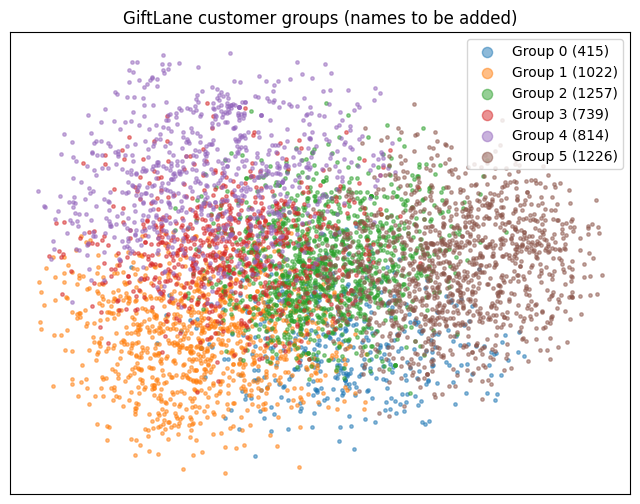

In [20]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

Z = normalize(svd.transform(B))                       # customer factors, volume removed

# Choose number of groups (3 to 6) by silhouette score
sil = {}
for c in range(3, 7):
    lab = KMeans(n_clusters=c, random_state=42, n_init=10).fit_predict(Z)
    sil[c] = silhouette_score(Z, lab, sample_size=3000, random_state=42)
    print(f"{c} groups: silhouette {sil[c]:.3f}")
n_groups = max(sil, key=sil.get)
labels = KMeans(n_clusters=n_groups, random_state=42, n_init=10).fit_predict(Z)

# Profile each group: size, basket size, countries, distinctive products (lift)
train = pd.read_parquet("data/processed/train.parquet")
country = train.groupby("Customer ID")["Country"].agg(lambda s: s.mode().iat[0])
cust_country = pd.Series(customers).map(country).values
Bd = B.tocsc()
share_all = np.asarray(B.mean(axis=0)).ravel()

for g in range(n_groups):
    m = labels == g
    share_g = np.asarray(B[m].mean(axis=0)).ravel()
    lift = np.where(share_g >= 0.10, share_g / np.maximum(share_all, 1e-9), 0)
    top = np.argsort(-lift)[:6]
    countries = pd.Series(cust_country[m]).value_counts(normalize=True).head(3)
    print(f"\n=== Group {g}: {m.sum()} customers ({m.mean():.0%}), "
          f"median {np.median(n_buyers_per_customer[m]):.0f} products each")
    print("Countries:", ", ".join(f"{c} {p:.0%}" for c, p in countries.items()))
    print("Distinctive products:", [name_of(j) for j in top])

# 2-D map for marketing (no customer IDs anywhere)
XY = PCA(n_components=2, random_state=42).fit_transform(Z)
plt.figure(figsize=(8, 6))
for g in range(n_groups):
    m = labels == g
    plt.scatter(XY[m, 0], XY[m, 1], s=6, alpha=0.5, label=f"Group {g} ({m.sum()})")
plt.legend(markerscale=3); plt.xticks([]); plt.yticks([])
plt.title("GiftLane customer groups (names to be added)")
plt.savefig("reports/ml6_customer_map_draft.png", dpi=150, bbox_inches="tight")
plt.show()

### ML6: Named segment map for marketing (R4: no customer IDs)
**What this cell does:** redraws the map with segment names and shares instead of numbers, and saves a summary table that is safe to share outside the team.

**Segments:** Vintage Tea Party (8%) · Kids' Crafts & Games (19%) · Cosy Comfort Gifts (23%, smallest baskets) · Party Supplies (14%, the most international) · Bags & Storage Bulk Buyers (15%, biggest baskets) · Romantic Home Décor (22%).

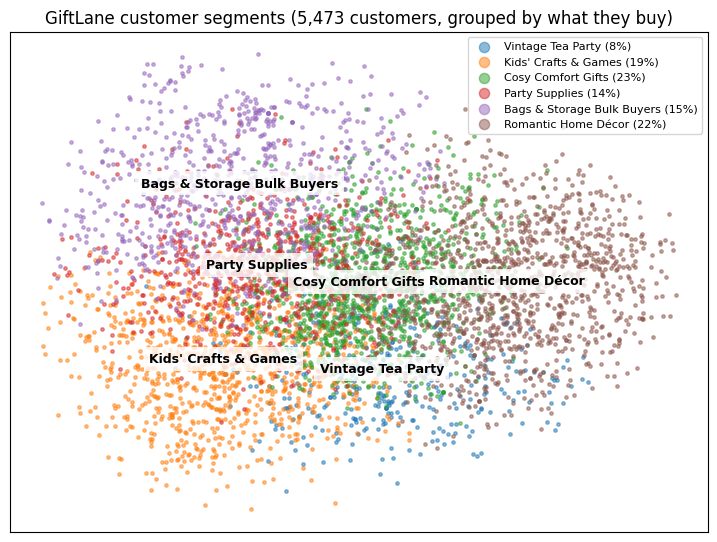

,segment,customers,share,median_products
0,Vintage Tea Party,415,8%,35
1,Kids' Crafts & Games,1022,19%,49
2,Cosy Comfort Gifts,1257,23%,23
3,Party Supplies,739,14%,55
4,Bags & Storage Bulk Buyers,814,15%,71
5,Romantic Home Décor,1226,22%,38


In [21]:
seg_names = {0: "Vintage Tea Party", 1: "Kids' Crafts & Games", 2: "Cosy Comfort Gifts",
             3: "Party Supplies", 4: "Bags & Storage Bulk Buyers", 5: "Romantic Home Décor"}

plt.figure(figsize=(9, 6.5))
for g in range(n_groups):
    m = labels == g
    plt.scatter(XY[m, 0], XY[m, 1], s=6, alpha=0.5,
                label=f"{seg_names[g]} ({m.mean():.0%})")
    cx, cy = np.median(XY[m], axis=0)
    plt.text(cx, cy, seg_names[g], fontsize=9, weight="bold", ha="center",
             bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
plt.legend(markerscale=3, loc="upper right", fontsize=8)
plt.xticks([]); plt.yticks([])
plt.title("GiftLane customer segments (5,473 customers, grouped by what they buy)")
plt.savefig("reports/ml6_customer_map.png", dpi=150, bbox_inches="tight")
plt.show()

summary = pd.DataFrame({
    "segment": [seg_names[g] for g in range(n_groups)],
    "customers": [int((labels == g).sum()) for g in range(n_groups)],
    "share": [f"{(labels == g).mean():.0%}" for g in range(n_groups)],
    "median_products": [int(np.median(n_buyers_per_customer[labels == g])) for g in range(n_groups)],
})
summary.to_csv("reports/ml6_segments.csv", index=False)
summary

## Git: save work to GitHub
**What this cell does:** commits and pushes all changes. Change `MSG` to describe what I did, then run this cell on its own. It is deliberately last, so **Runtime → Run before** reruns the analysis without committing anything. Before you commit, check that `git status` lists nothing from `data/`.

In [22]:
# Save work to GitHub. Run this cell on its own whenever you want to commit (not part of "Run all" checks).
MSG = "Describe what you changed"
!git add .
!git status
!git commit -m "{MSG}"
!git push

On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	modified:   reports/ml4_hit_rate_by_k.csv
	modified:   reports/ml5_pca_vs_svd.csv
	new file:   reports/ml6_customer_map_draft.png

[main 2a706ef] Describe what you changed
 3 files changed, 5 insertions(+), 5 deletions(-)
 create mode 100644 reports/ml6_customer_map_draft.png
Enumerating objects: 10, done.
Counting objects: 100% (10/10), done.
Delta compression using up to 2 threads
Compressing objects: 100% (6/6), done.
Writing objects: 100% (6/6), 385.86 KiB | 652.00 KiB/s, done.
Total 6 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/adiv031198/DS5020_Mini_Project_Group_AMA.git
   100f320..2a706ef  main -> main
